# Week 1 run: Project #11 (Hybrid transfer learning)
Runtime -> Change runtime type -> **T4 GPU** (speeds up feature extraction only). Run cells top to bottom.

In [11]:
# 1. Get the code. Replace with your repository URL.
!git clone https://github.com/aliarslan007/QML_Hybrid_Transfer_Learning_For_Medical_Images.git repo
%cd repo

Cloning into 'repo'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 53 (delta 8), reused 52 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 396.40 KiB | 8.62 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/repo/repo


In [12]:
# 2. Install (torch/torchvision are preinstalled on Colab)
!pip install -q pennylane medmnist pyyaml

In [13]:
!python -m pytest -q

.......                                                                  [100%]
7 passed in 7.12s


In [15]:
# 3. Features (~2 min on GPU)
!python scripts/01_extract_features.py

100% 214M/214M [02:28<00:00, 1.45MB/s]
train: X (4708, 512), positives 3494/4708
val  : X (524, 512), positives 389/524
test : X (624, 512), positives 390/624
Saved features to /content/repo/repo/features/pneumoniamnist_224_resnet18.npz


In [16]:
# 4. Fixed folds
!python scripts/02_make_folds.py

Training pool: 4708 images, pneumonia fraction 0.742
n=   50: 5 folds, pneumonia fraction 0.740-0.740
n=  100: 5 folds, pneumonia fraction 0.740-0.740
n=  250: 5 folds, pneumonia fraction 0.744-0.744
n=  500: 5 folds, pneumonia fraction 0.742-0.742
n= 1000: 5 folds, pneumonia fraction 0.742-0.742
Saved to /content/repo/repo/folds/pneumoniamnist_folds.json


In [17]:
# 5. Gradient check: must print PASS twice
!python scripts/05_gradient_check.py

d=4: 26 parameters, max |backprop - parameter-shift| = 1.91e-17 -> PASS
d=8: 50 parameters, max |backprop - parameter-shift| = 2.78e-17 -> PASS


In [18]:
# 6. Classical baselines (full grid)
!python scripts/03_run_classical.py

PCA d=4: explained variance 0.420
PCA d=8: explained variance 0.536
[ref512] n=50 fold=0 test AUROC=0.915
[ref512] n=50 fold=1 test AUROC=0.949
[ref512] n=50 fold=2 test AUROC=0.936
[ref512] n=50 fold=3 test AUROC=0.938
[ref512] n=50 fold=4 test AUROC=0.927
[ref512] n=100 fold=0 test AUROC=0.957
[ref512] n=100 fold=1 test AUROC=0.951
[ref512] n=100 fold=2 test AUROC=0.964
[ref512] n=100 fold=3 test AUROC=0.942
[ref512] n=100 fold=4 test AUROC=0.929
[ref512] n=250 fold=0 test AUROC=0.941
[ref512] n=250 fold=1 test AUROC=0.963
[ref512] n=250 fold=2 test AUROC=0.965
[ref512] n=250 fold=3 test AUROC=0.973
[ref512] n=250 fold=4 test AUROC=0.965
[ref512] n=500 fold=0 test AUROC=0.961
[ref512] n=500 fold=1 test AUROC=0.973
[ref512] n=500 fold=2 test AUROC=0.966
[ref512] n=500 fold=3 test AUROC=0.966
[ref512] n=500 fold=4 test AUROC=0.979
[ref512] n=1000 fold=0 test AUROC=0.976
[ref512] n=1000 fold=1 test AUROC=0.969
[ref512] n=1000 fold=2 test AUROC=0.977
[ref512] n=1000 fold=3 test AUROC=0.9

In [19]:
# 7. First quantum model: VQC pilot (d=4, all n, fold 0, seed 0)
!python scripts/04_run_vqc.py

0: ──RY(0.00)──RY(0.05)───RZ(0.02)───RY(0.10)─╭●───────╭X──RY(0.23)───RZ(0.00)───RY(-0.11)─╭●─── ···
1: ──RY(0.00)──RY(-0.05)──RZ(0.12)───RY(0.05)─╰X─╭●────│───RY(-0.04)──RZ(-0.01)──RY(-0.14)─╰X─╭● ···
2: ──RY(0.00)──RY(0.09)───RZ(-0.08)──RY(0.12)────╰X─╭●─│───RY(-0.10)──RZ(0.00)───RY(-0.13)────╰X ···
3: ──RY(0.00)──RY(-0.04)──RZ(0.14)───RY(0.00)───────╰X─╰●──RY(-0.00)──RZ(0.07)───RY(-0.03)────── ···

0: ··· ────╭X─┤  <Z>
1: ··· ────│──┤  <Z>
2: ··· ─╭●─│──┤  <Z>
3: ··· ─╰X─╰●─┤  <Z>
[vqc] d=4 n=50 fold=0 seed=0 params=26 val=0.943 test AUROC=0.838 (3.7s)
[vqc] d=4 n=100 fold=0 seed=0 params=26 val=0.969 test AUROC=0.915 (11.26s)
[vqc] d=4 n=250 fold=0 seed=0 params=26 val=0.958 test AUROC=0.904 (4.91s)
[vqc] d=4 n=500 fold=0 seed=0 params=26 val=0.969 test AUROC=0.910 (9.26s)
[vqc] d=4 n=1000 fold=0 seed=0 params=26 val=0.974 test AUROC=0.925 (16.46s)


                            mean     std  count
head            d   n                          
linear          4   50    0.8955  0.0227     15
                    100   0.9096  0.0089     15
                    250   0.9112  0.0075     15
                    500   0.9136  0.0041     15
                    1000  0.9150  0.0014     15
                8   50    0.8890  0.0482     15
                    100   0.8956  0.0445     15
                    250   0.9235  0.0146     15
                    500   0.9293  0.0040     15
                    1000  0.9317  0.0057     15
lr512_reference 512 50    0.9329  0.0128      5
                    100   0.9485  0.0134      5
                    250   0.9613  0.0119      5
                    500   0.9690  0.0072      5
                    1000  0.9717  0.0043      5
mlp             4   50    0.8779  0.0334     15
                    100   0.8994  0.0146     15
                    250   0.9055  0.0142     15
                    500   0.9170  0.0069

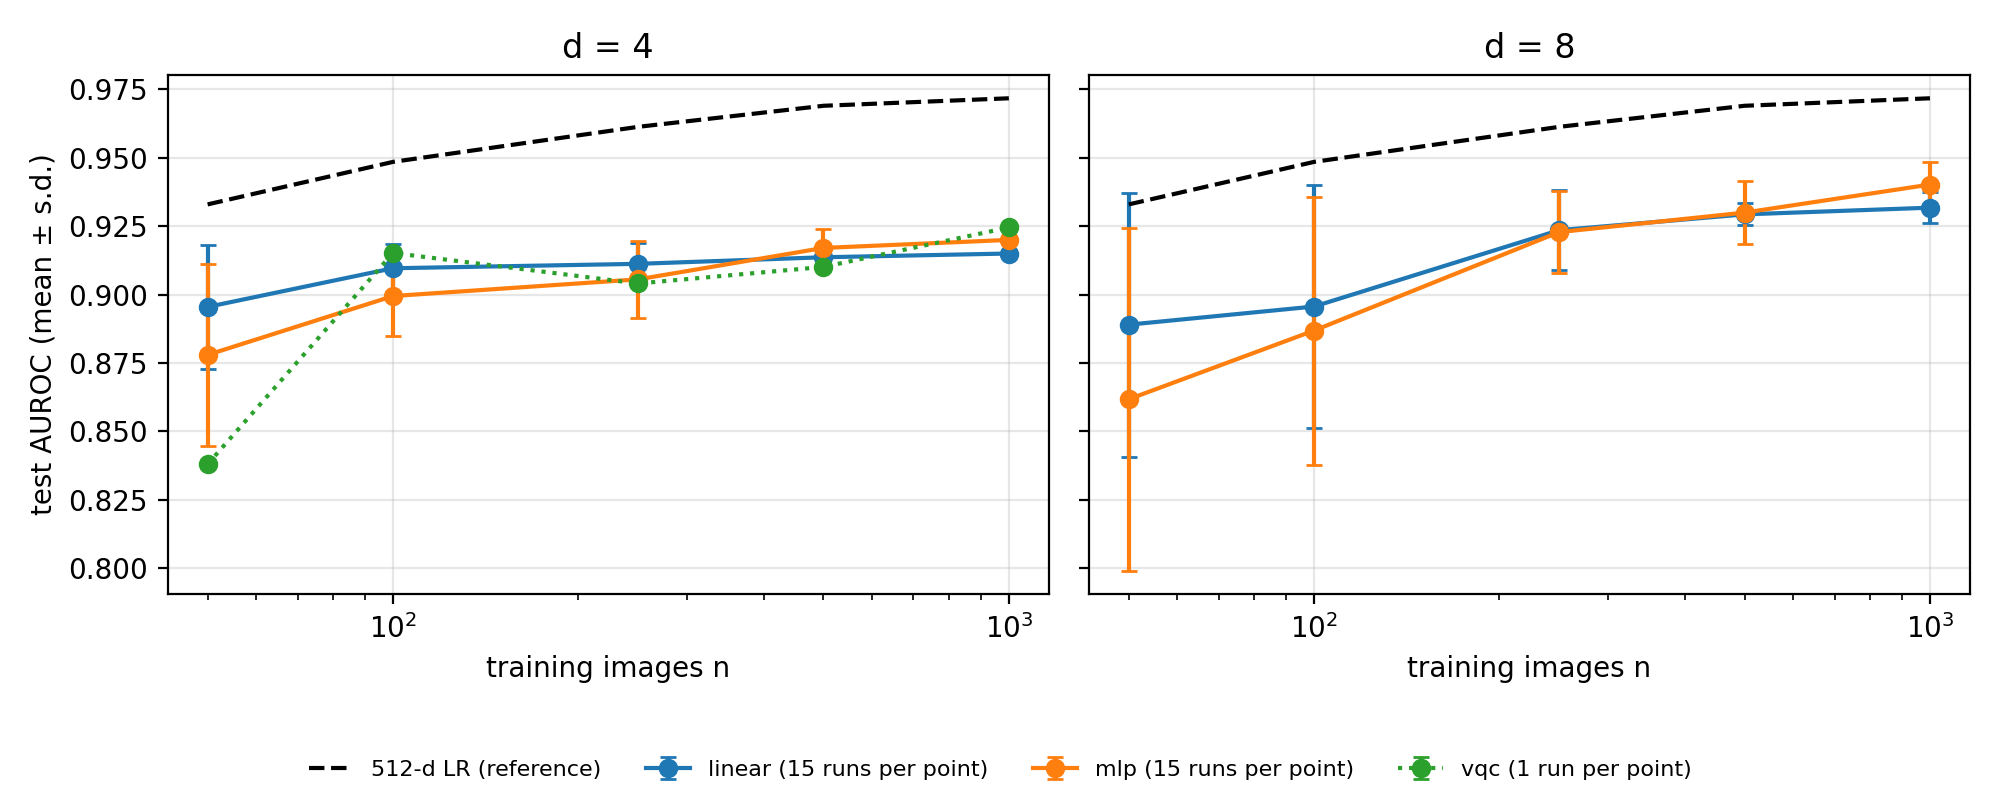

In [20]:
# 8. Summary + learning curves
!python scripts/06_summarize.py
from IPython.display import Image
Image('results/learning_curves.png')

In [21]:
# 9. Download folds + results to commit to GitHub
!zip -r week1_outputs.zip folds results
from google.colab import files
files.download('week1_outputs.zip')

  adding: folds/ (stored 0%)
  adding: folds/pneumoniamnist_folds.json (deflated 81%)
  adding: folds/.gitkeep (stored 0%)
  adding: results/ (stored 0%)
  adding: results/vqc.csv (deflated 55%)
  adding: results/classical.csv (deflated 69%)
  adding: results/learning_curves.png (deflated 10%)
  adding: results/.gitkeep (stored 0%)
  adding: results/summary.csv (deflated 68%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>